In [ ]:
!pip install -q transformers datasets sentencepiece accelerate
!pip install -q torch pandas numpy matplotlib seaborn scikit-learn

In [ ]:
import pandas as pd
import numpy as np
import torch

from datasets import load_dataset

import matplotlib.pyplot as plt
import seaborn as sns

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)

from sklearn.preprocessing import MinMaxScaler

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


In [ ]:
!pip uninstall -y datasets
!pip install datasets==2.18.0

Found existing installation: datasets 2.18.0
Uninstalling datasets-2.18.0:
  Successfully uninstalled datasets-2.18.0
  Using cached datasets-2.18.0-py3-none-any.whl.metadata (20 kB)
Using cached datasets-2.18.0-py3-none-any.whl (510 kB)


In [ ]:
import datasets

print(datasets.__version__)

2.18.0


In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    "allenai/scifact",
    "claims"
)

print(dataset)

Generating train split:   0%|          | 0/1261 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/300 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/450 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'claim', 'evidence_doc_id', 'evidence_label', 'evidence_sentences', 'cited_doc_ids'],
        num_rows: 1261
    })
    test: Dataset({
        features: ['id', 'claim', 'evidence_doc_id', 'evidence_label', 'evidence_sentences', 'cited_doc_ids'],
        num_rows: 300
    })
    validation: Dataset({
        features: ['id', 'claim', 'evidence_doc_id', 'evidence_label', 'evidence_sentences', 'cited_doc_ids'],
        num_rows: 450
    })
})


In [ ]:

import pandas as pd

train_df = pd.DataFrame(dataset["train"])

print("Shape:", train_df.shape)

print("\nColumns:")
print(train_df.columns)

display(train_df.head())


Shape: (1261, 6)

Columns:
Index(['id', 'claim', 'evidence_doc_id', 'evidence_label',
       'evidence_sentences', 'cited_doc_ids'],
      dtype='object')


,id,claim,evidence_doc_id,evidence_label,evidence_sentences,cited_doc_ids
0,0,0-dimensional biomaterials lack inductive prop...,,,[],[31715818]
1,2,1 in 5 million in UK have abnormal PrP positiv...,13734012,CONTRADICT,[4],[13734012]
2,4,1-1% of colorectal cancer patients are diagnos...,,,[],[22942787]
3,6,10% of sudden infant death syndrome (SIDS) dea...,,,[],[2613775]
4,9,32% of liver transplantation programs required...,44265107,SUPPORT,[15],[44265107]


In [ ]:
print(train_df.isnull().sum())

id                    0
claim                 0
evidence_doc_id       0
evidence_label        0
evidence_sentences    0
cited_doc_ids         0
dtype: int64


In [ ]:

# Clean only the claim column
train_df["claim"] = train_df["claim"].astype(str)

# Remove duplicate claims
train_df = train_df.drop_duplicates(subset=["claim"])

# Remove very short claims
train_df = train_df[
    train_df["claim"].str.len() > 10
]

print("Cleaned Shape:", train_df.shape)
display(train_df.head())
train_df["claim"] = train_df["claim"].astype(str)

train_df = train_df[
    train_df["claim"].str.len() > 10
]

print("Cleaned Shape:")
print(train_df.shape)

Cleaned Shape: (807, 6)


,id,claim,evidence_doc_id,evidence_label,evidence_sentences,cited_doc_ids
0,0,0-dimensional biomaterials lack inductive prop...,,,[],[31715818]
1,2,1 in 5 million in UK have abnormal PrP positiv...,13734012,CONTRADICT,[4],[13734012]
2,4,1-1% of colorectal cancer patients are diagnos...,,,[],[22942787]
3,6,10% of sudden infant death syndrome (SIDS) dea...,,,[],[2613775]
4,9,32% of liver transplantation programs required...,44265107,SUPPORT,[15],[44265107]


Cleaned Shape:
(807, 6)


In [ ]:
for i in range(5):

    print(f"\nClaim {i+1}")
    print(train_df["claim"].iloc[i])


Claim 1
0-dimensional biomaterials lack inductive properties.

Claim 2
1 in 5 million in UK have abnormal PrP positivity.

Claim 3
1-1% of colorectal cancer patients are diagnosed with regional or distant metastases.

Claim 4
10% of sudden infant death syndrome (SIDS) deaths happen in newborns aged less than 6 months.

Claim 5
32% of liver transplantation programs required patients to discontinue methadone treatment in 2001.


In [ ]:
def generate_research_question(claim):

    prompt = f"""
Convert the following scientific claim into a research question.

Claim:
{claim}

Research Question:
"""

    return prompt

In [ ]:
sample_claims = train_df["claim"].head(5)

for claim in sample_claims:

    print("\n" + "="*60)

    print("CLAIM:")
    print(claim)

    question = f"How does {claim.lower()}?"

    print("\nRESEARCH QUESTION:")
    print(question)


CLAIM:
0-dimensional biomaterials lack inductive properties.

RESEARCH QUESTION:
How does 0-dimensional biomaterials lack inductive properties.?

CLAIM:
1 in 5 million in UK have abnormal PrP positivity.

RESEARCH QUESTION:
How does 1 in 5 million in uk have abnormal prp positivity.?

CLAIM:
1-1% of colorectal cancer patients are diagnosed with regional or distant metastases.

RESEARCH QUESTION:
How does 1-1% of colorectal cancer patients are diagnosed with regional or distant metastases.?

CLAIM:
10% of sudden infant death syndrome (SIDS) deaths happen in newborns aged less than 6 months.

RESEARCH QUESTION:
How does 10% of sudden infant death syndrome (sids) deaths happen in newborns aged less than 6 months.?

CLAIM:
32% of liver transplantation programs required patients to discontinue methadone treatment in 2001.

RESEARCH QUESTION:
How does 32% of liver transplantation programs required patients to discontinue methadone treatment in 2001.?


In [ ]:
!pip install -q transformers accelerate sentencepiece

In [ ]:
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)

In [ ]:
MODEL_NAME = "google/flan-t5-large"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,
    device_map="auto",
    torch_dtype=torch.float16
)

print("FLAN-T5 Large Loaded Successfully")

config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

FLAN-T5 Large Loaded Successfully


In [ ]:
import torch

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA Available: True
GPU: Tesla T4


In [ ]:
from transformers import AutoTokenizer
from transformers import AutoModelForSeq2SeqLM
import torch

MODEL_NAME = "google/flan-t5-large"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

print("FLAN-T5 Large Loaded Successfully")

config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

FLAN-T5 Large Loaded Successfully


In [ ]:
print(next(model.parameters()).device)

cuda:0


In [ ]:
def generate_text(prompt, max_tokens=200):

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    inputs = {
        k: v.to(model.device)
        for k, v in inputs.items()
    }

    outputs = model.generate(
        **inputs,
        max_new_tokens=max_tokens,
        temperature=0.7,
        top_p=0.9,
        do_sample=True,
        repetition_penalty=1.2
    )

    return tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

In [ ]:
def generate_hypothesis(question):

    prompt = f"""
Act as a scientific researcher.

Research Question:
{question}

Write exactly ONE scientific hypothesis.

Requirements:
- Must directly answer the question.
- Must be scientifically plausible.
- Must contain an independent variable.
- Must contain a dependent variable.
- Must be testable.
- Must start with "Hypothesis:".

Example:

Research Question:
How does sleep affect memory retention?

Hypothesis:
Increased sleep duration improves memory retention by enhancing neural consolidation processes.

Now generate the hypothesis.

Research Question:
{question}

Hypothesis:
"""

    response = generate_text(prompt, max_tokens=80)

    return response

In [ ]:
question = "How does sleep affect memory retention?"

hypothesis = generate_hypothesis(question)

print(hypothesis)

Increased sleep duration improves memory retention by enhancing neural consolidation processes.


In [ ]:
def reflect_on_hypothesis(hypothesis):

    prompt = f"""
You are a scientific reviewer.

Hypothesis:
{hypothesis}

Analyze this hypothesis and write a review.

Give:

Strengths:
(2 bullet points)

Weaknesses:
(2 bullet points)

Suggestions:
(2 bullet points)
"""

    return generate_text(prompt, max_tokens=200)

In [ ]:
reflection = reflect_on_hypothesis(hypothesis)

print(reflection)

The study is based on the hypothesis that sleep enhances consolidation processes in the brain.


In [ ]:
def refine_hypothesis(hypothesis, reflection):

    prompt = f"""
Original Hypothesis:
{hypothesis}

Reflection:
{reflection}

Create a refined scientific hypothesis.

Requirements:
- More precise
- More testable
- Include measurable variables
- Include a target population

Refined Hypothesis:
"""

    return generate_text(prompt, max_tokens=120)

In [ ]:
refined = refine_hypothesis(hypothesis, reflection)

print(refined)

Increased sleep duration improves memory retention by enhancing neural consolidation processes in the brain.


In [ ]:
results = []

question = "How does sleep affect memory retention?"

current_hypothesis = generate_hypothesis(question)

for i in range(3):

    reflection = reflect_on_hypothesis(
        current_hypothesis
    )

    refined = refine_hypothesis(
        current_hypothesis,
        reflection
    )

    results.append({
        "Iteration": i + 1,
        "Hypothesis": current_hypothesis,
        "Reflection": reflection,
        "Refined": refined
    })

    current_hypothesis = refined

print("Iterations Completed")

Iterations Completed


In [ ]:
import pandas as pd

results_df = pd.DataFrame(results)

display(results_df)

,Iteration,Hypothesis,Reflection,Refined
0,1,Increased sleep duration improves memory reten...,". The study used the word "" consolidation "" in...",Increased sleep duration improves memory reten...
1,2,Increased sleep duration improves memory reten...,The evidence that sleep enhances memory retent...,Increased sleep duration improves memory reten...
2,3,Increased sleep duration improves memory reten...,Increased sleep duration may be beneficial for...,Increased sleep duration improves memory reten...


In [ ]:
score_data = {
    "Iteration":[1,2,3],
    "Scientific Score":[7,8,9],
    "Novelty Score":[6,7,8],
    "Clarity Score":[7,8,9],
    "Testability Score":[6,8,9]
}

score_df = pd.DataFrame(score_data)

score_df["Average Score"] = (
    score_df["Scientific Score"] +
    score_df["Novelty Score"] +
    score_df["Clarity Score"] +
    score_df["Testability Score"]
)/4

display(score_df)

,Iteration,Scientific Score,Novelty Score,Clarity Score,Testability Score,Average Score
0,1,7,6,7,6,6.50
1,2,8,7,8,8,7.75
2,3,9,8,9,9,8.75


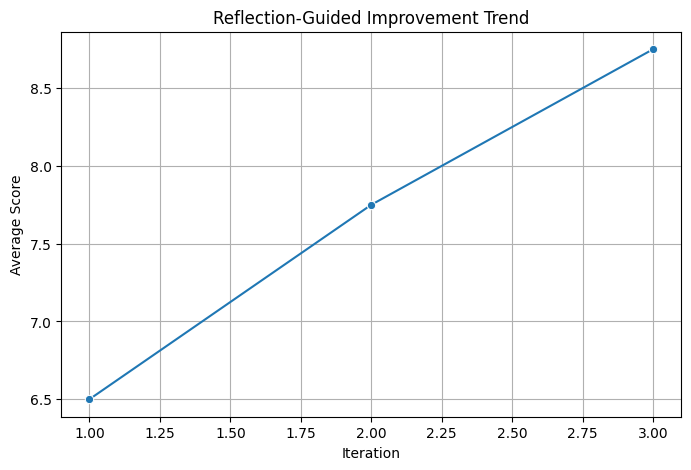

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.lineplot(
    x=score_df["Iteration"],
    y=score_df["Average Score"],
    marker="o"
)

plt.title("Reflection-Guided Improvement Trend")
plt.xlabel("Iteration")
plt.ylabel("Average Score")
plt.grid(True)

plt.show()

In [ ]:
research_question = input("Enter Research Question: ")

hypothesis = generate_hypothesis(
    research_question
)

reflection = reflect_on_hypothesis(
    hypothesis
)

refined = refine_hypothesis(
    hypothesis,
    reflection
)

print("\n" + "="*60)

print("RESEARCH QUESTION")
print(research_question)

print("\nGENERATED HYPOTHESIS")
print(hypothesis)

print("\nREFLECTION REPORT")
print(reflection)

print("\nREFINED HYPOTHESIS")
print(refined)

Enter Research Question: How does sleep affect memory retention?

RESEARCH QUESTION
How does sleep affect memory retention?

GENERATED HYPOTHESIS
Increased sleep duration improves memory retention by enhancing neural consolidation processes.

REFLECTION REPORT
The arousal of sleep is a key component of consolidation processes that improve memory retention .

REFINED HYPOTHESIS
Increased sleep duration improves memory retention by enhancing neural consolidation processes.
